<a href="https://colab.research.google.com/github/Birravoooo20/Concrete-Compressive-Strength-Prediction/blob/main/03_model_improvement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part C — Meningkatkan Model dan Membandingkan Hasil

Di Part B, kita membuat baseline **Multiple Linear Regression** untuk memperkirakan kuat tekan beton. Pada Part C, kita membandingkannya dengan **Random Forest Regressor**, model yang dapat menangkap pola non-linear dan interaksi fitur.

Kita akan membandingkan kedua model dengan pembagian data uji yang sama, memakai cross-validation pada data latihan, lalu memeriksa error model terbaik. Random Forest tidak selalu lebih baik; hasil evaluasi yang akan menentukan.

## 1. Memuat library dan dataset

Jalankan sel ini di Google Colab. Dataset berasal dari UCI Concrete Compressive Strength. Kita menyiapkan fitur dan target seperti pada Part B.

In [3]:
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

concrete = fetch_ucirepo(id=165)
df = pd.concat([concrete.data.features, concrete.data.targets], axis=1)

X = df.drop(columns="Concrete compressive strength")
y = df["Concrete compressive strength"]

print("Ukuran dataset:", df.shape)
print("Fitur:", X.columns.tolist())

Ukuran dataset: (1030, 9)
Fitur: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']


## 2. Membagi data dengan cara yang sama

Kita gunakan kembali `test_size=0.2` dan `random_state=42` seperti Part B. Ini membuat perbandingan pada data uji lebih adil. Data uji tetap tidak dipakai untuk memilih atau melatih model.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data latihan:", X_train.shape)
print("Data uji:", X_test.shape)

Data latihan: (824, 8)
Data uji: (206, 8)


## 3. Menyiapkan model pembanding

Model pertama adalah regresi linear sebagai baseline Part B. Model kedua adalah Random Forest dengan 300 pohon. `random_state` menjaga hasil Random Forest tetap dapat direproduksi.

Parameter ini merupakan titik awal sederhana, bukan hasil pencarian parameter terbaik.

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    print(nama, "selesai dilatih")

Linear Regression selesai dilatih
Random Forest selesai dilatih


## 4. Membandingkan performa pada data uji

MAE dan RMSE dilaporkan dalam MPa; nilai lebih rendah berarti error lebih kecil. R² yang lebih tinggi berarti model menjelaskan lebih banyak variasi target pada data uji. Gunakan metrik bersama-sama, karena tidak satu pun menceritakan seluruh kualitas model.

In [6]:
baris_hasil = []

for nama, model in models.items():
    prediksi = model.predict(X_test)
    mse = mean_squared_error(y_test, prediksi)

    baris_hasil.append({
        "Model": nama,
        "MAE (MPa)": mean_absolute_error(y_test, prediksi),
        "RMSE (MPa)": np.sqrt(mse),
        "R²": r2_score(y_test, prediksi)
    })

hasil_uji = pd.DataFrame(baris_hasil).set_index("Model")
display(hasil_uji.round(3))

,MAE (MPa),RMSE (MPa),R²
Model,,,
Linear Regression,7.746,9.796,0.628
Random Forest,3.789,5.541,0.881


## 5. Cross-validation pada data latihan

Satu pembagian latihan/uji dapat memberi hasil yang kebetulan tinggi atau rendah. Cross-validation membagi **data latihan** menjadi lima lipatan: model dilatih dan dinilai bergantian pada lipatan yang berbeda. Data uji tetap disimpan untuk evaluasi akhir.

Kita bandingkan rata-rata MAE dan R² dari lima lipatan. Skor MAE dibuat positif agar mudah dibaca.

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

baris_cv = []

for nama, model in models.items():
    skor = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    mae_lipatan = -skor["test_mae"]
    r2_lipatan = skor["test_r2"]

    baris_cv.append({
        "Model": nama,
        "Rata-rata MAE (MPa)": mae_lipatan.mean(),
        "Simpangan baku MAE": mae_lipatan.std(),
        "Rata-rata R²": r2_lipatan.mean(),
        "Simpangan baku R²": r2_lipatan.std()
    })

hasil_cv = pd.DataFrame(baris_cv).set_index("Model")
display(hasil_cv.round(3))

,Rata-rata MAE (MPa),Simpangan baku MAE,Rata-rata R²,Simpangan baku R²
Model,,,,
Linear Regression,8.422,0.406,0.597,0.047
Random Forest,3.669,0.242,0.900,0.016


## 6. Memeriksa prediksi dan residual

Pilih model berdasarkan gabungan hasil cross-validation dan kebutuhan penggunaan. Untuk latihan ini, kita memilih model dengan MAE cross-validation terkecil, lalu melihat hasil data ujinya.

Residual didefinisikan sebagai **aktual − prediksi**. Residual positif berarti model memprediksi terlalu rendah, sedangkan residual negatif berarti model memprediksi terlalu tinggi. Pola residual yang menyebar tanpa bentuk tertentu biasanya lebih diharapkan daripada pola lengkung atau kipas.

Model pilihan berdasarkan MAE cross-validation: Random Forest
MAE data uji:  3.79 MPa
RMSE data uji: 5.54 MPa
R² data uji:   0.881


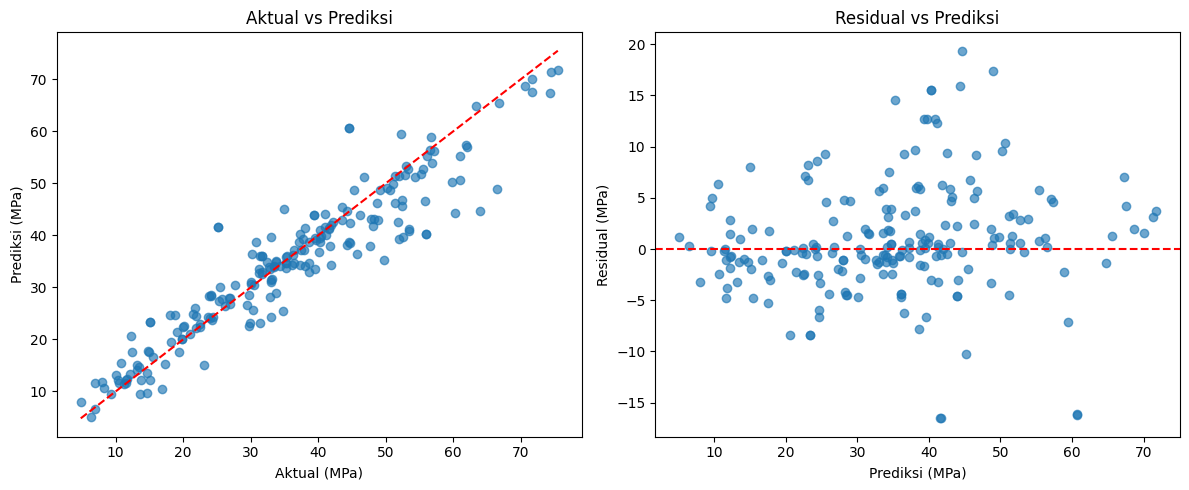

In [8]:
model_terbaik_nama = hasil_cv["Rata-rata MAE (MPa)"].idxmin()
model_terbaik = models[model_terbaik_nama]
prediksi_terbaik = model_terbaik.predict(X_test)
residual = y_test.to_numpy() - prediksi_terbaik

print("Model pilihan berdasarkan MAE cross-validation:", model_terbaik_nama)
print(f"MAE data uji:  {mean_absolute_error(y_test, prediksi_terbaik):.2f} MPa")
print(f"RMSE data uji: {np.sqrt(mean_squared_error(y_test, prediksi_terbaik)):.2f} MPa")
print(f"R² data uji:   {r2_score(y_test, prediksi_terbaik):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, prediksi_terbaik, alpha=0.65)
batas = [
    min(y_test.min(), prediksi_terbaik.min()),
    max(y_test.max(), prediksi_terbaik.max())
]
axes[0].plot(batas, batas, "r--")
axes[0].set(
    xlabel="Aktual (MPa)",
    ylabel="Prediksi (MPa)",
    title="Aktual vs Prediksi"
)

axes[1].scatter(prediksi_terbaik, residual, alpha=0.65)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(
    xlabel="Prediksi (MPa)",
    ylabel="Residual (MPa)",
    title="Residual vs Prediksi"
)

plt.tight_layout()
plt.show()

## 7. Melihat fitur yang dipakai Random Forest

Random Forest menyediakan `feature_importances_`, yaitu ukuran seberapa sering fitur membantu mengurangi ketidakmurnian pada pohon. Nilainya relatif terhadap model dan dataset ini; nilai tersebut bukan bukti sebab-akibat dan tidak menunjukkan arah pengaruh.

,Feature importance
Fly Ash,0.018632
Coarse Aggregate,0.027341
Fine Aggregate,0.035848
Superplasticizer,0.055045
Blast Furnace Slag,0.076811
Water,0.124154
Cement,0.328734
Age,0.333434


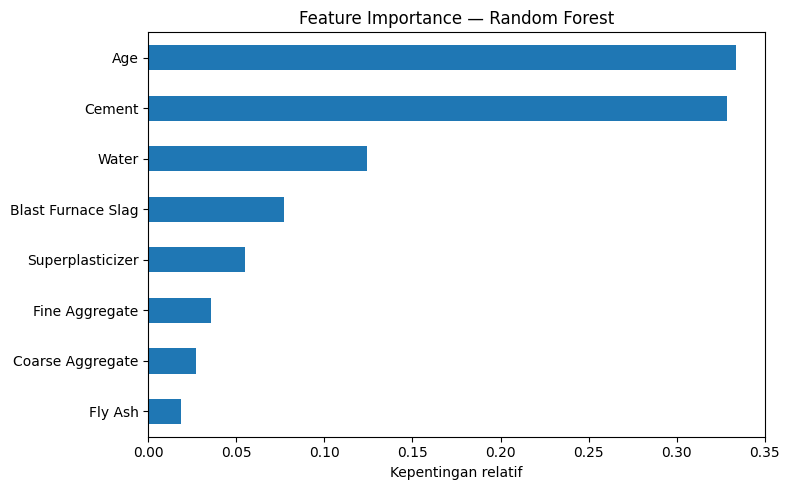

In [9]:
if model_terbaik_nama == "Random Forest":
    importance = pd.Series(
        model_terbaik.feature_importances_,
        index=X.columns
    ).sort_values()

    display(importance.to_frame("Feature importance"))

    importance.plot(
        kind="barh",
        figsize=(8, 5),
        title="Feature Importance — Random Forest"
    )
    plt.xlabel("Kepentingan relatif")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Model pilihan adalah Linear Regression; "
        "feature_importances_ hanya tersedia pada Random Forest."
    )

## 8. Ringkasan dan refleksi

Bandingkan hasil Part C dengan baseline Part B. Catat metrik dan model yang digunakan sebelum menyimpulkan apakah model baru membantu. Perbedaan kecil antar model dapat berubah jika dataset atau cara pembagian berubah.

1. Model mana yang memiliki MAE cross-validation paling rendah? Apakah hasil data uji mendukung pilihan itu?
2. Mengapa cross-validation dilakukan pada data latihan, sementara data uji tetap disisihkan?
3. Apa arti residual positif dan negatif pada grafik?
4. Apakah fitur teratas pada feature importance dapat disebut penyebab kuat tekan? Jelaskan.
5. Jika model akan dipakai di luar data latihan ini, pemeriksaan tambahan apa yang perlu dilakukan?

**Simpan notebook** setelah mengisi jawaban refleksi dan mencatat hasil yang kamu peroleh.